# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Cohen 2021's multiple-myeloma malignant manifold is a **round, diffuse cloud** (aspect ≈ 1),
not a Y and not an elongated strip. The three embryonic signatures resolve into a single
dominant developmental contrast — a Gast/pSom-high pole opposing a terminal Crest-high pole —
so the topology is **non-branching**: we fit a scFates `curve` (not a `tree`), keep all cells on
their original joint embedding (no re-embedding of a linear compartment), and check the fitted
curve for folds explicitly.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Cells stay on their joint embedding coordinates (`X_umap` / house `X_umap_lin`) — no
re-embedding. The three modules (Gast / pSom / Crest) are scored with `score_genes` against the
`union` control pool, then **graph-smoothed** (kNN-connectivity averaging) for reading geography
and correlations; raw per-cell scores are retained for the deliverable UMAPs.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, s, _ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present | mean {adata.obs[lab].mean():+.4f}')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 33067 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.08
Gast: 69/81 genes present | mean -0.0218
pSom: 80/98 genes present | mean +0.0143
Crest: 101/104 genes present | mean +0.0013


### Scope decision — whole manifold vs a sub-lobe (data-driven)
Low-resolution Leiden and a proliferation check test whether the developmental axis is confined
to one lobe (the Kürten/Zhou scoping case) or spans the whole manifold. Here Leiden(0.15)
returns a single lobe carrying all samples, cycling is negligible (shallow MARS-seq) and
uncorrelated with any module, and the Crest-high cells are distributed across the cloud — so the
developmental axis is a global gradient. **Keep the whole manifold.**

In [4]:
sc.pp.neighbors(adata, n_pcs=21, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S','G2/M','Intermediate'])
print('lobes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
cyc = adata.obs['cycling'].values.astype(float)
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs cycling: rho = {rho:+.2f}')
print('-> single lobe, cycling orthogonal to modules; keep whole manifold (no scoping).')
sub = adata

lobes: {'0': 33067}
cycling fraction per lobe: {'0': 0.028}
smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.07
  Crest_sm vs Gast_sm: r = -0.69
  Crest_sm vs pSom_sm: r = -0.61
  Gast vs cycling: rho = -0.06
  pSom vs cycling: rho = +0.03
  Crest vs cycling: rho = -0.03
-> single lobe, cycling orthogonal to modules; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph) with an explicit fold check
The self-approach ratio (minimum distance between graph-non-adjacent nodes / median edge length)
must exceed 1 for a fold-free backbone, and the graph must have 0 forks (a curve, not a tree).

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

curve: 2 tips, 0 forks | fold self-approach ratio = 2.54 (>1 = fold-free)


### Derive the root (data-driven, developmental order)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin.
Crest is developmentally **late**, so pseudotime flows from the Gast/pSom pole toward the
Crest-high terminus (never rooted at the Crest tip).

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
Rr = np.asarray(sub.obsm['X_R']); hard = Rr.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0202 pSom=+0.0150 Crest=+0.0009
tip 2: Gast=-0.0223 pSom=+0.0145 Crest=-0.0001
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.238 p=0.0e+00
  pSom_sm: rho=-0.096 p=2.1e-68
  Crest_sm: rho=-0.042 p=3.3e-14


### House orientation, verified against pseudotime
The house orientation (rigid rotation stored as `X_umap_lin` in 01) is confirmed to align with
the pseudotime gradient, so all trajectory panels share one consistent left→right layout.

In [7]:
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
# orient so pseudotime increases left->right
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = -r
print(f'corr(x_lin, pseudotime) = {r:+.2f} (house orientation aligns with developmental axis)')

corr(x_lin, pseudotime) = +0.89 (house orientation aligns with developmental axis)


### Render the fitted curve on the embedding (fold audit) + save manifold figure

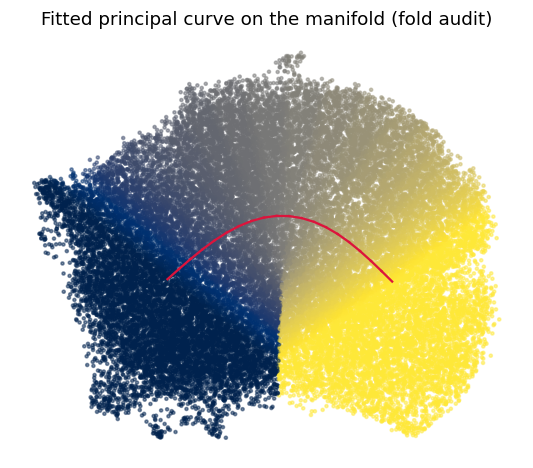

In [8]:
# curve node positions -> project into the house linear frame for the audit render
F = sub.uns['graph']['F'].T
xy = sub.obsm['X_umap']; c0 = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c0, full_matrices=False)
ang = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-ang),-np.sin(-ang)],[np.sin(-ang),np.cos(-ang)]])
Fr = (F - xy.mean(0)) @ Rm.T
# match the same x-flip applied to X_umap_lin (sign fixed by pseudotime corr)
if np.corrcoef((c0@Rm.T)[:,0], t)[0,1] < 0: Fr[:,0] = -Fr[:,0]
xl = sub.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(6,5))
ax.scatter(xl[:,0], xl[:,1], c=t, cmap='cividis', s=4, alpha=.5)
for a in range(B.shape[0]):
    for b in range(a+1, B.shape[0]):
        if B[a,b] > 0: ax.plot([Fr[a,0],Fr[b,0]],[Fr[a,1],Fr[b,1]],'-', color='crimson', lw=1.5)
ax.set_title('Fitted principal curve on the manifold (fold audit)'); ax.axis('off')
plt.show()

saved manifold.h5ad + manifold.pdf


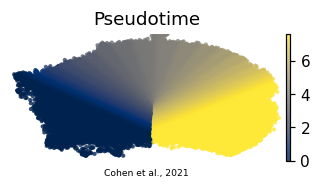

In [9]:
# sanitize non-serializable ElPiGraph uns entry, then save
if 'epg' in sub.uns:
    sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg'].get('NodePositions', F))}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Cohen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')